# EfficientNet melanoma training and evaluation

Notebook workflow based on `train.py` and `test.py`: configure the run, prepare patient-grouped cross-validation, inspect the model architecture, train one fold while tracking validation ROC-AUC, then evaluate the saved best checkpoint on the untouched `test_cleaned.csv` holdout.

In [16]:
# Imports shared by the training and testing workflow.
import argparse
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedGroupKFold
from torch import nn
from torch.utils.data import DataLoader

from test import evaluate as evaluate_test, load_test_data, resolve_device
from train import (
    EfficientNetMelanoma,
    MelanomaDataset,
    build_metadata_features,
    load_training_data,
    set_seed,
    train_one_epoch,
    evaluate as evaluate_training,
)

ROOT = Path.cwd()
if not (ROOT / 'train.py').is_file() or not (ROOT / 'test.py').is_file():
    raise FileNotFoundError('Run this notebook from the CV project directory.')
ARTIFACTS = ROOT / 'artifacts'
ARTIFACTS.mkdir(exist_ok=True)

## Training arguments — ISIC 2020 train/test split

Use the JPEG cache and `train_cleaned.csv`, which contains the ISIC 2020 train+validation portion only. `test_cleaned.csv` remains held out and is evaluated only after training. This excludes DICM and excludes all test-set IDs from training.

In [17]:
# Train EfficientNet-B0 using only the frozen ISIC 2020 train split.
train_cache_dir = ROOT / 'artifacts' / 'jpeg_256'
train_csv = ROOT / 'train_cleaned.csv'
train_output = ROOT / 'artifacts' / 'efficientnet_combined_notebook_fold0.pt'
backbone = 'efficientnet_b0'
image_size = 256
epochs = 15
train_batch_size = 32
train_log_interval = 25
learning_rate = 3e-4
weight_decay = 1e-4
n_folds = 5
fold = 0
num_workers = min(4, os.cpu_count() or 1)
seed = 42
pretrained = True
use_metadata = True
train_amp = True

train_config = argparse.Namespace(
    cache_dir=train_cache_dir,
    train_csv=train_csv,
    output=train_output,
    backbone=backbone,
    image_size=image_size,
    epochs=epochs,
    batch_size=train_batch_size,
    log_interval=train_log_interval,
    learning_rate=learning_rate,
    weight_decay=weight_decay,
    n_folds=n_folds,
    fold=fold,
    num_workers=num_workers,
    seed=seed,
    pretrained=pretrained,
    use_metadata=use_metadata,
    amp=train_amp,
)
for name, value in vars(train_config).items():
    print(f'{name}: {value}')

cache_dir: /home/bhandead/Projects/CV/artifacts/jpeg_256
train_csv: /home/bhandead/Projects/CV/train_cleaned.csv
output: /home/bhandead/Projects/CV/artifacts/efficientnet_combined_notebook_fold0.pt
backbone: efficientnet_b0
image_size: 256
epochs: 15
batch_size: 32
log_interval: 25
learning_rate: 0.0003
weight_decay: 0.0001
n_folds: 5
fold: 0
num_workers: 4
seed: 42
pretrained: True
use_metadata: True
amp: True


## Test argument variables

Use the same JPEG cache for image lookup and `test_cleaned.csv` for evaluation. Only test CSV rows are scored; the cache's other rows are not sent through the evaluation loader.

In [18]:
# Test only on the frozen ISIC 2020 holdout; use the same JPEG cache as training.
checkpoint_path = train_output
cache_dir = ROOT / 'artifacts' / 'jpeg_256'
test_csv = ROOT / 'test_cleaned.csv'
batch_size = 32
test_num_workers = min(4, os.cpu_count() or 1)
test_log_interval = 50
device = 'auto'  # one of: 'auto', 'cpu', 'cuda'
amp = True
output_predictions = ROOT / 'artifacts' / 'efficientnet_combined_notebook_test_predictions.csv'
output_metrics = ROOT / 'artifacts' / 'efficientnet_combined_notebook_test_metrics.json'

## Ablation study flag

In [19]:
# Optional test-time metadata ablation; disabled unless explicitly enabled.
# This zeroes encoded metadata inputs at inference (no checkpoint retraining).
run_metadata_ablation = True

## Optional overrides and runtime configuration

`argument_overrides` can override any CLI-style argument by destination name. Leave it empty to use the editable defaults above.

In [20]:
# Test evaluator runtime configuration; training has its own separate arguments above.
argument_overrides = {}
runtime_values = {
    'checkpoint': checkpoint_path,
    'cache_dir': cache_dir,
    'test_csv': test_csv,
    'batch_size': batch_size,
    'num_workers': test_num_workers,
    'log_interval': test_log_interval,
    'device': device,
    'amp': amp,
    'output_predictions': output_predictions,
    'output_metrics': output_metrics,
}
unknown_arguments = set(argument_overrides) - set(runtime_values)
if unknown_arguments:
    raise ValueError(f'Unsupported argument override(s): {sorted(unknown_arguments)}')
runtime_values.update(argument_overrides)
args = argparse.Namespace(**runtime_values)

if args.batch_size < 1 or args.num_workers < 0 or args.log_interval < 1:
    raise ValueError('batch-size/log-interval must be positive and num-workers non-negative.')
if args.device not in {'auto', 'cpu', 'cuda'}:
    raise ValueError("device must be 'auto', 'cpu', or 'cuda'.")
print('Test configuration:')
for argument_name, argument_value in vars(args).items():
    print(f'  {argument_name}: {argument_value}')

Test configuration:
  checkpoint: /home/bhandead/Projects/CV/artifacts/efficientnet_combined_notebook_fold0.pt
  cache_dir: /home/bhandead/Projects/CV/artifacts/jpeg_256
  test_csv: /home/bhandead/Projects/CV/test_cleaned.csv
  batch_size: 32
  num_workers: 4
  log_interval: 50
  device: auto
  amp: True
  output_predictions: /home/bhandead/Projects/CV/artifacts/efficientnet_combined_notebook_test_predictions.csv
  output_metrics: /home/bhandead/Projects/CV/artifacts/efficientnet_combined_notebook_test_metrics.json


## Reusable evaluation flow

The utility methods below are reused from `test.py` for data matching, metadata encoding, device selection, and batch evaluation. This wrapper preserves the script’s validation and output logic.

In [21]:
def prepare_evaluation(args):
    """Validate inputs, match test rows to the cache, and build the evaluation loader."""
    if not args.checkpoint.is_file():
        raise FileNotFoundError(f'Model checkpoint not found: {args.checkpoint}')
    checkpoint = torch.load(args.checkpoint, map_location='cpu', weights_only=True)
    model_config = checkpoint.get('model_config')
    if not isinstance(model_config, dict):
        raise ValueError('Checkpoint does not contain a valid model_config.')

    backbone_name = str(model_config['backbone'])
    model_image_size = int(model_config['image_size'])
    model_uses_metadata = bool(model_config['use_metadata'])
    metadata_feature_count = int(model_config['metadata_features'])
    if model_uses_metadata != (metadata_feature_count > 0):
        raise ValueError('Checkpoint metadata configuration is inconsistent.')

    images, indices, encoded_metadata, matched_test_frame = load_test_data(
        args.test_csv,
        args.cache_dir,
        model_uses_metadata,
        checkpoint.get('metadata_schema'),
    )
    labels = matched_test_frame['target_test'].to_numpy(dtype=np.int64)
    if encoded_metadata is not None and encoded_metadata.shape[1] != metadata_feature_count:
        raise ValueError(
            f'Checkpoint expects {metadata_feature_count} metadata features, got {encoded_metadata.shape[1]}.'
        )

    # The dataset indexes labels and metadata by cache row; fill selected test rows only.
    dataset_labels = np.zeros(len(images), dtype=np.int64)
    dataset_labels[indices] = labels
    dataset_metadata = None
    if encoded_metadata is not None:
        dataset_metadata = np.zeros((len(images), metadata_feature_count), dtype=np.float32)
        dataset_metadata[indices] = encoded_metadata

    evaluation_device = resolve_device(args.device)
    evaluation_amp = args.amp and evaluation_device.type == 'cuda'
    dataset = MelanomaDataset(
        images=images,
        labels=dataset_labels,
        indices=indices,
        image_size=model_image_size,
        training=False,
        metadata=dataset_metadata,
    )
    loader = DataLoader(
        dataset,
        batch_size=args.batch_size,
        shuffle=False,
        num_workers=args.num_workers,
        pin_memory=evaluation_device.type == 'cuda',
        persistent_workers=args.num_workers > 0,
    )
    return {
        'checkpoint': checkpoint,
        'backbone': backbone_name,
        'image_size': model_image_size,
        'use_metadata': model_uses_metadata,
        'metadata_features': metadata_feature_count,
        'images': images,
        'indices': indices,
        'labels': labels,
        'test_frame': matched_test_frame,
        'device': evaluation_device,
        'amp_enabled': evaluation_amp,
        'loader': loader,
    }


def run_model_inference(prepared):
    """Initialize/load the trained checkpoint and evaluate its test batches."""
    model = EfficientNetMelanoma(
        backbone_name=prepared['backbone'],
        pretrained=False,
        metadata_features=prepared['metadata_features'],
    ).to(prepared['device'])
    model.load_state_dict(prepared['checkpoint']['model_state_dict'], strict=True)
    actual_labels, probabilities, test_loss = evaluate_test(
        model,
        prepared['loader'],
        prepared['device'],
        prepared['use_metadata'],
        prepared['amp_enabled'],
        args.log_interval,
    )
    return model, actual_labels, probabilities, test_loss


def save_evaluation_outputs(args, prepared, actual_labels, probabilities, test_loss):
    """Compute and save the same metrics and per-image predictions as test.py."""
    malignant_probabilities = probabilities[:, 1]
    predicted_labels = probabilities.argmax(axis=1)
    metrics = {
        'checkpoint': str(args.checkpoint.resolve()),
        'test_csv': str(args.test_csv.resolve()),
        'n_test': int(len(actual_labels)),
        'class_counts': {
            'benign': int((actual_labels == 0).sum()),
            'malignant': int((actual_labels == 1).sum()),
        },
        'loss': test_loss,
        'accuracy': float(accuracy_score(actual_labels, predicted_labels)),
        'roc_auc': float(roc_auc_score(actual_labels, malignant_probabilities)),
        'average_precision': float(average_precision_score(actual_labels, malignant_probabilities)),
        'precision_malignant': float(precision_score(actual_labels, predicted_labels, zero_division=0)),
        'recall_malignant': float(recall_score(actual_labels, predicted_labels, zero_division=0)),
        'f1_malignant': float(f1_score(actual_labels, predicted_labels, zero_division=0)),
        'confusion_matrix_labels_0_1': confusion_matrix(
            actual_labels, predicted_labels, labels=[0, 1]
        ).tolist(),
        'log_loss': float(log_loss(actual_labels, probabilities, labels=[0, 1])),
        'checkpoint_validation_roc_auc': prepared['checkpoint'].get('validation_roc_auc'),
        'device': str(prepared['device']),
        'amp_enabled': prepared['amp_enabled'],
    }
    predictions = pd.DataFrame({
        'image_name': prepared['test_frame']['image_name'].to_numpy(),
        'target': actual_labels,
        'predicted_target': predicted_labels,
        'benign_probability': probabilities[:, 0],
        'malignant_probability': malignant_probabilities,
    })
    args.output_predictions.parent.mkdir(parents=True, exist_ok=True)
    args.output_metrics.parent.mkdir(parents=True, exist_ok=True)
    predictions.to_csv(args.output_predictions, index=False)
    args.output_metrics.write_text(json.dumps(metrics, indent=2) + '\n', encoding='utf-8')
    print(json.dumps(metrics, indent=2))
    print(f'Saved predictions: {args.output_predictions}')
    print(f'Saved metrics: {args.output_metrics}')
    return metrics, predictions

## Prepare training data and cross-validation fold

Loads the configured cache, optionally filters it by `train_csv`, and creates the requested stratified patient-grouped fold. Metadata preprocessing is fit using the training partition only.

In [31]:
if train_config.image_size < 32 or train_config.epochs < 1 or train_config.batch_size < 1 or train_config.log_interval < 1:
    raise ValueError('image-size must be >=32, and epochs/batch-size/log-interval must be positive.')
if not 0 <= train_config.fold < train_config.n_folds:
    raise ValueError('fold must be in [0, n-folds).')

set_seed(train_config.seed)
train_images, train_frame = load_training_data(train_config.cache_dir, train_config.train_csv)
train_labels = train_frame['target'].to_numpy(dtype=np.int64)
patient_groups = train_frame['patient_group'].astype(str).to_numpy()
cv_splitter = StratifiedGroupKFold(
    n_splits=train_config.n_folds,
    shuffle=True,
    random_state=train_config.seed,
)
train_indices, validation_indices = list(
    cv_splitter.split(np.zeros(len(train_labels)), train_labels, patient_groups)
)[train_config.fold]
if set(train_labels[train_indices]) != {0, 1} or set(train_labels[validation_indices]) != {0, 1}:
    raise ValueError('Both train and validation folds must contain benign and malignant images.')
if not set(patient_groups[train_indices]).isdisjoint(patient_groups[validation_indices]):
    raise RuntimeError('Patient leakage detected between train and validation folds.')

metadata_features = None
metadata_schema = None
if train_config.use_metadata:
    metadata_features, metadata_schema = build_metadata_features(train_frame, train_indices)

train_dataset = MelanomaDataset(
    train_images, train_labels, train_indices, train_config.image_size,
    training=True, metadata=metadata_features,
)
validation_dataset = MelanomaDataset(
    train_images, train_labels, validation_indices, train_config.image_size,
    training=False, metadata=metadata_features,
)
training_device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
training_amp_enabled = train_config.amp and training_device.type == 'cuda'
loader_options = {
    'batch_size': train_config.batch_size,
    'num_workers': train_config.num_workers,
    'pin_memory': training_device.type == 'cuda',
    'persistent_workers': train_config.num_workers > 0,
}
train_loader = DataLoader(train_dataset, shuffle=True, **loader_options)
validation_loader = DataLoader(validation_dataset, shuffle=False, **loader_options)

train_model = EfficientNetMelanoma(
    backbone_name=train_config.backbone,
    pretrained=train_config.pretrained,
    metadata_features=metadata_features.shape[1] if metadata_features is not None else 0,
).to(training_device)
class_counts = np.bincount(train_labels[train_indices], minlength=2)
class_weights = len(train_indices) / (2.0 * class_counts)
criterion = nn.CrossEntropyLoss(
    weight=torch.tensor(class_weights, dtype=torch.float32, device=training_device)
)
optimizer = torch.optim.Adam(
    train_model.parameters(), lr=train_config.learning_rate, weight_decay=train_config.weight_decay
)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=train_config.epochs)
scaler = torch.amp.GradScaler('cuda', enabled=training_amp_enabled)

print(
    f"Cache rows: {len(train_frame):,}; train fold: {len(train_indices):,}; "
    f"validation fold: {len(validation_indices):,}; device: {training_device}; "
    f"training patients: {len(set(patient_groups[train_indices])):,}; "
    f"validation patients: {len(set(patient_groups[validation_indices])):,}"
)

Frozen training set: train_cleaned.csv | images=28,027 | patients=1,761
Cache rows: 28,027; train fold: 22,421; validation fold: 5,606; device: cuda; training patients: 1,407; validation patients: 354


## Model architecture

Render an architecture diagram for the selected EfficientNet backbone, optional metadata encoder, dropout ensemble, and binary classifier before training starts.

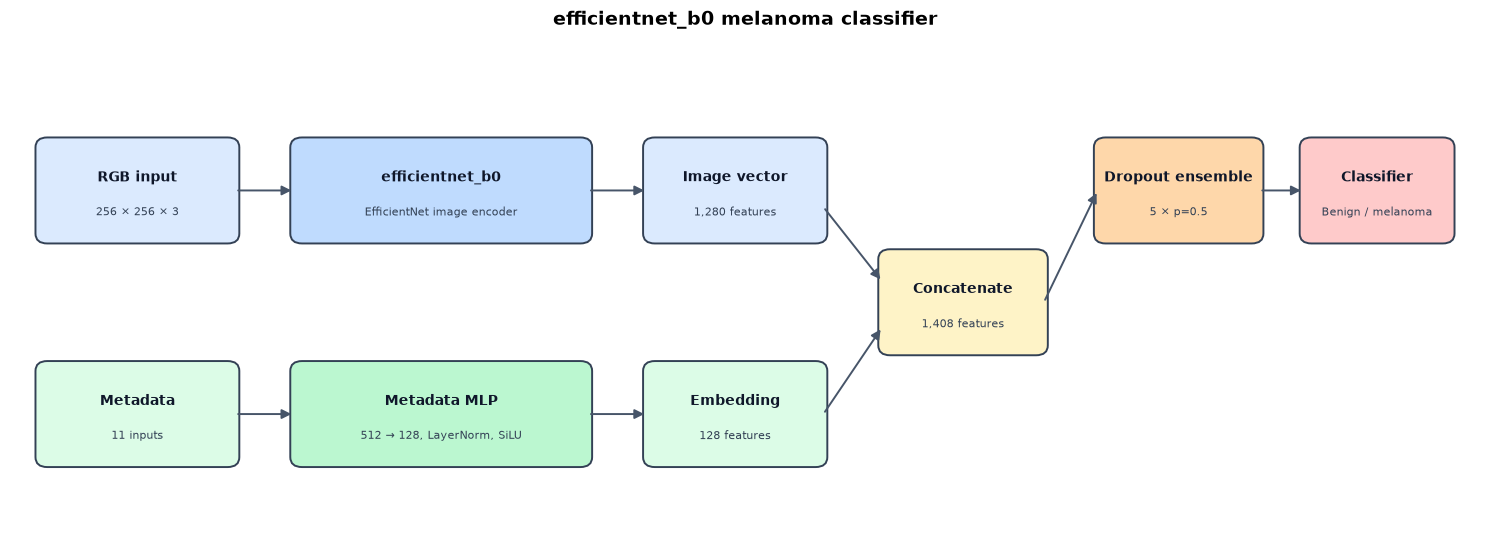

Trainable parameters: 4,083,454


In [7]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def draw_model_box(ax, x, y, width, height, title, detail, color):
    ax.add_patch(FancyBboxPatch(
        (x, y), width, height, boxstyle='round,pad=0.04,rounding_size=0.12',
        linewidth=1.4, edgecolor='#334155', facecolor=color,
    ))
    ax.text(x + width / 2, y + height * 0.63, title, ha='center', va='center',
            fontsize=10, weight='bold', color='#0f172a')
    ax.text(x + width / 2, y + height * 0.28, detail, ha='center', va='center',
            fontsize=8, color='#334155')

def draw_model_arrow(ax, start, end):
    ax.add_patch(FancyArrowPatch(start, end, arrowstyle='-|>', mutation_scale=14,
                                 linewidth=1.4, color='#475569'))

image_features_count = train_model.classifier.in_features
metadata_embedding_count = 0
if train_model.metadata_encoder is not None:
    metadata_embedding_count = 128
    image_features_count -= metadata_embedding_count

fig, ax = plt.subplots(figsize=(15, 5.5))
ax.set_xlim(0, 15)
ax.set_ylim(0, 6)
ax.axis('off')
draw_model_box(ax, 0.3, 3.5, 2.0, 1.2, 'RGB input', f'{train_config.image_size} × {train_config.image_size} × 3', '#dbeafe')
draw_model_box(ax, 2.9, 3.5, 3.0, 1.2, train_config.backbone, 'EfficientNet image encoder', '#bfdbfe')
draw_model_box(ax, 6.5, 3.5, 1.8, 1.2, 'Image vector', f'{image_features_count:,} features', '#dbeafe')
draw_model_arrow(ax, (2.3, 4.1), (2.9, 4.1))
draw_model_arrow(ax, (5.9, 4.1), (6.5, 4.1))
if train_model.metadata_encoder is not None:
    draw_model_box(ax, 0.3, 0.8, 2.0, 1.2, 'Metadata', f'{metadata_features.shape[1]} inputs', '#dcfce7')
    draw_model_box(ax, 2.9, 0.8, 3.0, 1.2, 'Metadata MLP', '512 → 128, LayerNorm, SiLU', '#bbf7d0')
    draw_model_box(ax, 6.5, 0.8, 1.8, 1.2, 'Embedding', f'{metadata_embedding_count} features', '#dcfce7')
    draw_model_arrow(ax, (2.3, 1.4), (2.9, 1.4))
    draw_model_arrow(ax, (5.9, 1.4), (6.5, 1.4))
    draw_model_box(ax, 8.9, 2.15, 1.65, 1.2, 'Concatenate', f'{train_model.classifier.in_features:,} features', '#fef3c7')
    draw_model_arrow(ax, (8.3, 3.9), (8.9, 3.0))
    draw_model_arrow(ax, (8.3, 1.4), (8.9, 2.45))
else:
    draw_model_box(ax, 8.9, 3.5, 1.65, 1.2, 'Image vector', f'{image_features_count:,} features', '#fef3c7')
    draw_model_arrow(ax, (8.3, 4.1), (8.9, 4.1))
draw_model_box(ax, 11.1, 3.5, 1.65, 1.2, 'Dropout ensemble', '5 × p=0.5', '#fed7aa')
draw_model_box(ax, 13.2, 3.5, 1.5, 1.2, 'Classifier', 'Benign / melanoma', '#fecaca')
draw_model_arrow(ax, (10.55, 2.75 if train_model.metadata_encoder is not None else 4.1), (11.1, 4.1))
draw_model_arrow(ax, (12.75, 4.1), (13.2, 4.1))
ax.set_title(f'{train_config.backbone} melanoma classifier', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()
print(f'Trainable parameters: {sum(p.numel() for p in train_model.parameters() if p.requires_grad):,}')

## Train the selected fold

Runs the training loop from `train.py`, records loss and validation ROC-AUC/AP each epoch, and saves the best checkpoint by validation ROC-AUC plus the fold history.

In [8]:
train_config.output.parent.mkdir(parents=True, exist_ok=True)
best_validation_auc = -1.0
training_history = []

for epoch in range(1, train_config.epochs + 1):
    train_loss = train_one_epoch(
        train_model, train_loader, optimizer, scaler, training_device,
        train_config.use_metadata, training_amp_enabled, criterion,
        epoch, train_config.epochs, train_config.log_interval,
    )
    validation_loss, validation_auc, validation_ap = evaluate_training(
        train_model, validation_loader, training_device,
        train_config.use_metadata, training_amp_enabled,
        epoch, train_config.epochs, train_config.log_interval,
    )
    current_lr = float(optimizer.param_groups[0]['lr'])
    training_history.append({
        'epoch': epoch,
        'learning_rate': current_lr,
        'train_loss': train_loss,
        'validation_loss': validation_loss,
        'validation_roc_auc': validation_auc,
        'validation_average_precision': validation_ap,
    })
    print(
        f'Epoch {epoch:02d}/{train_config.epochs} | lr={current_lr:.2e} '
        f'train_loss={train_loss:.4f} val_loss={validation_loss:.4f} '
        f'val_auc={validation_auc:.4f} val_ap={validation_ap:.4f}'
    )

    if validation_auc > best_validation_auc:
        best_validation_auc = validation_auc
        torch.save({
            'model_state_dict': train_model.state_dict(),
            'model_config': {
                'backbone': train_config.backbone,
                'image_size': train_config.image_size,
                'use_metadata': train_config.use_metadata,
                'metadata_features': metadata_features.shape[1] if metadata_features is not None else 0,
            },
            'metadata_schema': metadata_schema,
            'class_names': ['benign', 'malignant'],
            'validation_roc_auc': validation_auc,
            'fold': train_config.fold,
            'seed': train_config.seed,
        }, train_config.output)
    scheduler.step()

training_history_frame = pd.DataFrame(training_history)
history_path = train_config.output.with_name(f'{train_config.output.stem}_history.csv')
training_history_frame.to_csv(history_path, index=False)
print(f'Best validation ROC-AUC: {best_validation_auc:.4f}')
print(f'Saved best checkpoint: {train_config.output}')
print(f'Saved training history: {history_path}')

Epoch 01/15 | train batch 1/857 | samples 32/27,411 | loss 0.7644 | 0.7 img/s | 44.0s
Epoch 01/15 | train batch 25/857 | samples 800/27,411 | loss 0.3607 | 17.6 img/s | 45.5s
Epoch 01/15 | train batch 50/857 | samples 1,600/27,411 | loss 0.3355 | 34.0 img/s | 47.0s
Epoch 01/15 | train batch 75/857 | samples 2,400/27,411 | loss 0.3121 | 49.3 img/s | 48.6s
Epoch 01/15 | train batch 100/857 | samples 3,200/27,411 | loss 0.2914 | 63.6 img/s | 50.3s
Epoch 01/15 | train batch 125/857 | samples 4,000/27,411 | loss 0.2720 | 77.1 img/s | 51.9s
Epoch 01/15 | train batch 150/857 | samples 4,800/27,411 | loss 0.2635 | 89.9 img/s | 53.4s
Epoch 01/15 | train batch 175/857 | samples 5,600/27,411 | loss 0.2561 | 101.9 img/s | 55.0s
Epoch 01/15 | train batch 200/857 | samples 6,400/27,411 | loss 0.2551 | 113.1 img/s | 56.6s
Epoch 01/15 | train batch 225/857 | samples 7,200/27,411 | loss 0.2471 | 123.7 img/s | 58.2s
Epoch 01/15 | train batch 250/857 | samples 8,000/27,411 | loss 0.2358 | 133.7 img/s | 5

## Prepare held-out test inputs

Runs only after training finishes. The test cache should use the combined-cache preprocessing representation and include holdout image pixels; inference still selects only rows listed in `test_cleaned.csv`.

In [25]:
# Prepare the frozen test split using JPEG cache rows. No test rows are included in training.
args.checkpoint = train_config.output
args.cache_dir = ROOT / 'artifacts' / 'jpeg_256'
args.test_csv = ROOT / 'test_cleaned.csv'
prepared = prepare_evaluation(args)
print(f"Prepared {len(prepared['labels']):,} held-out test images on {prepared['device']}.")

================WARNING: No train CSV provided; loading the full cache.================================Ensure this is intended behavior for your use case.================
Full cache loaded: images=32,701 | patients=2,056
Prepared 4,674 held-out test images on cuda.


## Load model and run inference

This standalone execution cell performs checkpoint model initialization/loading and evaluation only. Run after the input-preparation cell.

In [26]:
model, actual_labels, probabilities, test_loss = run_model_inference(prepared)

Test batch 1/147 | samples 32/4,674 | loss 0.1819 | 3.1s
Test batch 50/147 | samples 1,600/4,674 | loss 0.4189 | 3.9s
Test batch 100/147 | samples 3,200/4,674 | loss 0.4427 | 4.9s
Test batch 147/147 | samples 4,674/4,674 | loss 0.4390 | 7.6s


## Save outputs and inspect metrics

This writes the same JSON metrics and per-image prediction CSV as `test.py`, to the configured output paths.

In [27]:
metrics, predictions = save_evaluation_outputs(args, prepared, actual_labels, probabilities, test_loss)

{
  "checkpoint": "/home/bhandead/Projects/CV/artifacts/efficientnet_combined_notebook_fold0.pt",
  "test_csv": "/home/bhandead/Projects/CV/test_cleaned.csv",
  "n_test": 4674,
  "class_counts": {
    "benign": 4592,
    "malignant": 82
  },
  "loss": 0.43896062954603526,
  "accuracy": 0.8416773641420625,
  "roc_auc": 0.8258477096966091,
  "average_precision": 0.10243733009118046,
  "precision_malignant": 0.06824146981627296,
  "recall_malignant": 0.6341463414634146,
  "f1_malignant": 0.12322274881516587,
  "confusion_matrix_labels_0_1": [
    [
      3882,
      710
    ],
    [
      30,
      52
    ]
  ],
  "log_loss": 0.43895143270492554,
  "checkpoint_validation_roc_auc": 0.9912694696173373,
  "device": "cuda",
  "amp_enabled": true
}
Saved predictions: /home/bhandead/Projects/CV/artifacts/efficientnet_combined_notebook_test_predictions.csv
Saved metrics: /home/bhandead/Projects/CV/artifacts/efficientnet_combined_notebook_test_metrics.json


## Parity checks

Verify the notebook outputs preserve the test CSV ordering and labels, then recompute core metrics from the emitted prediction file. Since preprocessing and evaluation helpers are imported from `test.py`, this also guards against data-selection or metric-output drift.

In [28]:
saved_predictions = pd.read_csv(args.output_predictions)
saved_metrics = json.loads(args.output_metrics.read_text(encoding='utf-8'))
expected_names = prepared['test_frame']['image_name'].astype(str).to_numpy()
expected_labels = actual_labels.astype(np.int64)

assert saved_predictions['image_name'].astype(str).to_numpy().tolist() == expected_names.tolist(), 'Saved prediction image order differs from test.py flow.'
assert np.array_equal(saved_predictions['target'].to_numpy(dtype=np.int64), expected_labels), 'Saved test labels differ.'
assert len(saved_predictions) == len(pd.read_csv(args.test_csv)), 'Prediction row count differs from test CSV.'
assert saved_metrics['n_test'] == len(expected_labels), 'Metrics row count differs.'
assert np.isclose(saved_metrics['accuracy'], accuracy_score(expected_labels, saved_predictions['predicted_target']))
assert np.isclose(saved_metrics['roc_auc'], roc_auc_score(expected_labels, saved_predictions['malignant_probability']))
assert np.isclose(saved_metrics['average_precision'], average_precision_score(expected_labels, saved_predictions['malignant_probability']))
print('Parity checks passed: test rows/order/labels and recomputed accuracy, ROC-AUC, and average precision match saved outputs.')

Parity checks passed: test rows/order/labels and recomputed accuracy, ROC-AUC, and average precision match saved outputs.


### Validation and held-out test ROC-AUC curves

The final cell compares validation and test ROC curves using the best validation-AUC checkpoint, and shows validation ROC-AUC across training epochs. The test set is for final reporting only.

Test confusion matrix (rows=true, columns=predicted; labels=[benign, melanoma]):
[[3882  710]
 [  30   52]]
Validation ROC-AUC (best checkpoint): 0.8741
Test ROC-AUC: 0.8258


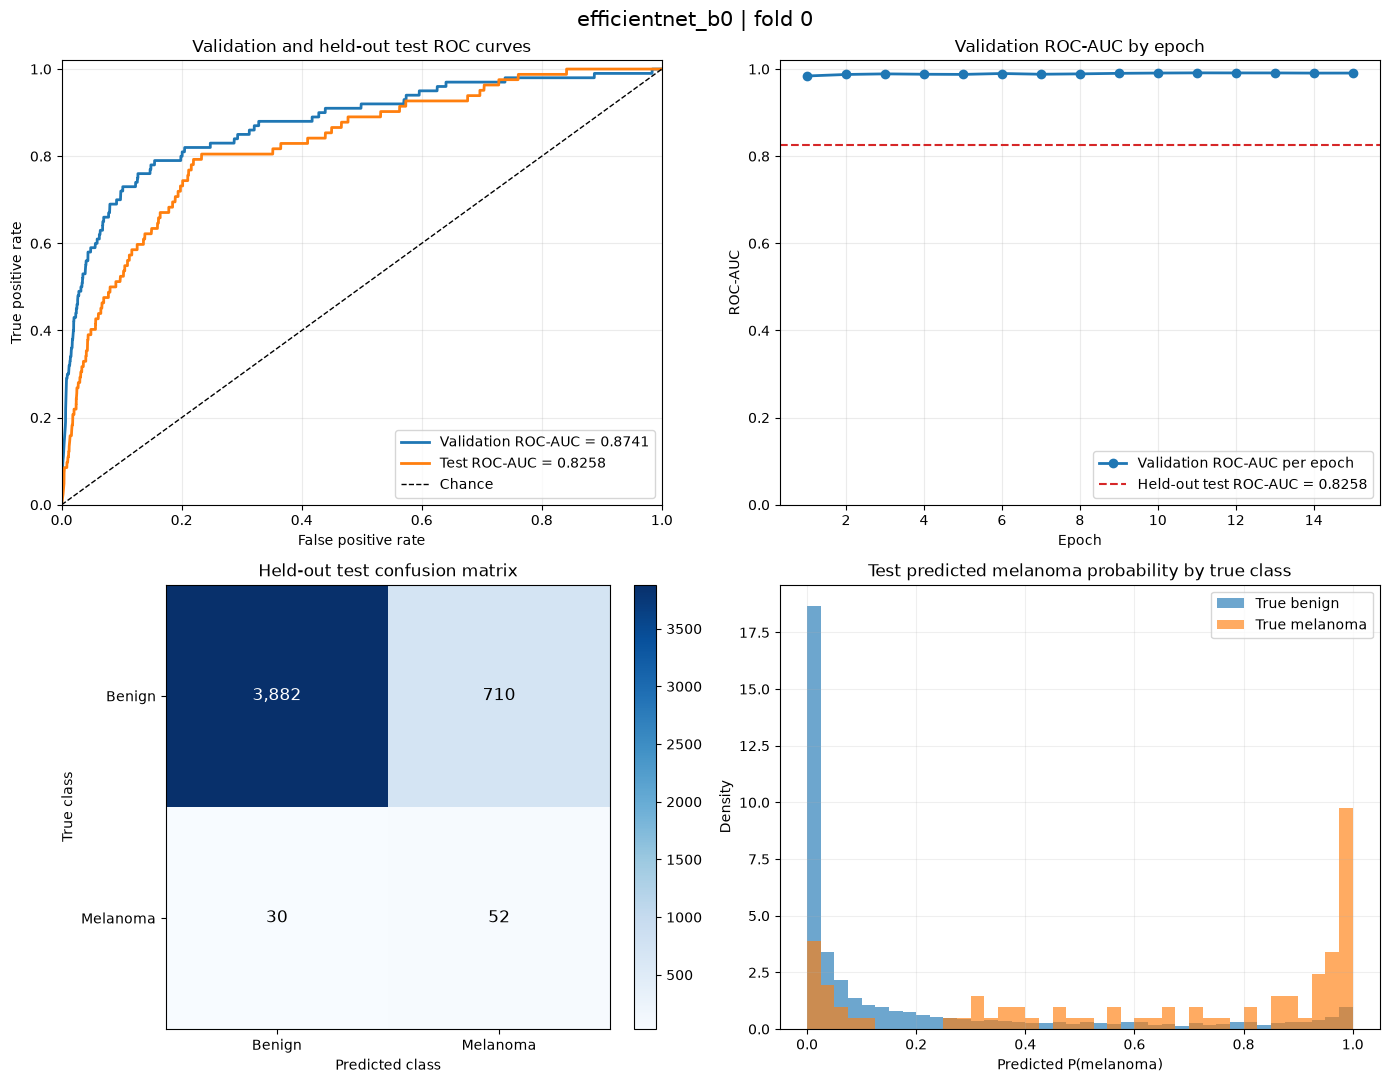

Saved ROC, confusion matrix, and probability-distribution plots: /home/bhandead/Projects/CV/artifacts/validation_test_roc_curves.png


In [34]:
# Final diagnostics: validation/test ROC curves, validation ROC-AUC by epoch,
# held-out test confusion matrix, and test malignant-score distributions by true class.
from sklearn.metrics import roc_curve, auc

if 'training_history_frame' not in globals():
    history_path = train_config.output.with_name(f'{train_config.output.stem}_history.csv')
    if not history_path.is_file():
        raise FileNotFoundError(f'Training history CSV not found: {history_path}')
    training_history_frame = pd.read_csv(history_path)


def collect_scores(model, loader, device, use_metadata, amp_enabled):
    model.eval()
    all_labels = []
    all_scores = []
    with torch.inference_mode():
        for images, metadata_batch, labels_batch in loader:
            images = images.to(device, non_blocking=True)
            labels_batch = labels_batch.to(device, non_blocking=True)
            metadata_batch = metadata_batch.to(device, non_blocking=True) if use_metadata else None
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp_enabled):
                logits = model(images, metadata_batch)
            all_labels.append(labels_batch.cpu().numpy())
            all_scores.append(logits.softmax(dim=1)[:, 1].float().cpu().numpy())
    return np.concatenate(all_labels), np.concatenate(all_scores)

validation_y, validation_scores = collect_scores(
    model, validation_loader, prepared['device'], prepared['use_metadata'], prepared['amp_enabled']
)
test_y = actual_labels.astype(np.int64)
test_scores = probabilities[:, 1]
test_predicted_labels = probabilities.argmax(axis=1)
test_confusion = confusion_matrix(test_y, test_predicted_labels, labels=[0, 1])
test_auc = roc_auc_score(test_y, test_scores)
validation_auc_best_checkpoint = roc_auc_score(validation_y, validation_scores)

print('Test confusion matrix (rows=true, columns=predicted; labels=[benign, melanoma]):')
print(test_confusion)
print(f'Validation ROC-AUC (best checkpoint): {validation_auc_best_checkpoint:.4f}')
print(f'Test ROC-AUC: {test_auc:.4f}')

fig, axes = plt.subplots(2, 2, figsize=(14, 11))

# ROC curves
for curve_name, y_true, score in (
    ('Validation', validation_y, validation_scores),
    ('Test', test_y, test_scores),
):
    fpr, tpr, _ = roc_curve(y_true, score)
    roc_auc_value = auc(fpr, tpr)
    axes[0, 0].plot(fpr, tpr, linewidth=2, label=f'{curve_name} ROC-AUC = {roc_auc_value:.4f}')
axes[0, 0].plot([0, 1], [0, 1], 'k--', linewidth=1, label='Chance')
axes[0, 0].set(
    title='Validation and held-out test ROC curves',
    xlabel='False positive rate',
    ylabel='True positive rate',
    xlim=(0, 1),
    ylim=(0, 1.02),
)
axes[0, 0].grid(alpha=0.25)
axes[0, 0].legend(loc='lower right')

# Validation ROC-AUC over epochs; test ROC-AUC is shown only as a final reference.
axes[0, 1].plot(
    training_history_frame['epoch'],
    training_history_frame['validation_roc_auc'],
    marker='o',
    linewidth=2,
    label='Validation ROC-AUC per epoch',
)
axes[0, 1].axhline(
    test_auc, color='tab:red', linestyle='--', label=f'Held-out test ROC-AUC = {test_auc:.4f}'
)
axes[0, 1].set(
    title='Validation ROC-AUC by epoch',
    xlabel='Epoch',
    ylabel='ROC-AUC',
    ylim=(0, 1.02),
)
axes[0, 1].grid(alpha=0.25)
axes[0, 1].legend(loc='lower right')

# Test confusion matrix
image = axes[1, 0].imshow(test_confusion, cmap='Blues')
axes[1, 0].set(
    title='Held-out test confusion matrix',
    xlabel='Predicted class',
    ylabel='True class',
    xticks=[0, 1],
    yticks=[0, 1],
    xticklabels=['Benign', 'Melanoma'],
    yticklabels=['Benign', 'Melanoma'],
)
threshold = test_confusion.max() / 2 if test_confusion.size else 0
for row in range(2):
    for column in range(2):
        axes[1, 0].text(
            column, row, f'{test_confusion[row, column]:,}',
            ha='center', va='center',
            color='white' if test_confusion[row, column] > threshold else 'black',
            fontsize=12,
        )
fig.colorbar(image, ax=axes[1, 0], fraction=0.046, pad=0.04)

# Test malignant probability distribution grouped by true label
probability_bins = np.linspace(0, 1, 41)
axes[1, 1].hist(
    test_scores[test_y == 0], bins=probability_bins, alpha=0.65,
    label='True benign', density=True,
)
axes[1, 1].hist(
    test_scores[test_y == 1], bins=probability_bins, alpha=0.65,
    label='True melanoma', density=True,
)
axes[1, 1].set(
    title='Test predicted melanoma probability by true class',
    xlabel='Predicted P(melanoma)',
    ylabel='Density',
)
axes[1, 1].legend()
axes[1, 1].grid(alpha=0.2)

fig.suptitle(f'{train_config.backbone} | fold {train_config.fold}', fontsize=15)
plt.tight_layout()
plot_path = args.output_metrics.parent / 'validation_test_roc_curves.png'
plt.savefig(plot_path, dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved ROC, confusion matrix, and probability-distribution plots: {plot_path}')

In [37]:
if not run_metadata_ablation:
    print('Metadata ablation is disabled. Set run_metadata_ablation = True to run it.')
else:
    if 'prepared' not in globals() or 'model' not in globals():
        raise RuntimeError('Run the standard test preparation and inference cells before this ablation cell.')
    if not prepared['use_metadata'] or prepared['metadata_features'] == 0:
        print('Metadata ablation skipped: this checkpoint does not use metadata.')
    else:
        # Ablate only the metadata input at test time; the trained checkpoint is unchanged.
        test_dataset = prepared['loader'].dataset
        original_dataset_metadata = test_dataset.metadata
        if original_dataset_metadata is None:
            raise RuntimeError('The prepared test dataset has no metadata to ablate.')

        try:
            test_dataset.metadata = np.zeros_like(original_dataset_metadata)
            # Use a fresh single-process loader so persistent workers from the baseline
            # loader cannot keep using their old, non-ablated dataset copy.
            ablation_loader = DataLoader(
                test_dataset,
                batch_size=args.batch_size,
                shuffle=False,
                num_workers=0,
                pin_memory=prepared['device'].type == 'cuda',
            )
            ablated_labels, ablated_probabilities, ablated_loss = evaluate_test(
                model,
                ablation_loader,
                prepared['device'],
                prepared['use_metadata'],
                prepared['amp_enabled'],
                args.log_interval,
            )
        finally:
            test_dataset.metadata = original_dataset_metadata

        if not np.array_equal(ablated_labels, actual_labels):
            raise RuntimeError('Ablation evaluation labels do not match the baseline test labels.')

        baseline_predictions = probabilities.argmax(axis=1)
        ablated_predictions = ablated_probabilities.argmax(axis=1)
        baseline_summary = {
            'loss': float(test_loss),
            'accuracy': float(accuracy_score(actual_labels, baseline_predictions)),
            'roc_auc': float(roc_auc_score(actual_labels, probabilities[:, 1])),
            'average_precision': float(average_precision_score(actual_labels, probabilities[:, 1])),
            'confusion_matrix_labels_0_1': confusion_matrix(
                actual_labels, baseline_predictions, labels=[0, 1]
            ).tolist(),
        }
        ablated_summary = {
            'loss': float(ablated_loss),
            'accuracy': float(accuracy_score(ablated_labels, ablated_predictions)),
            'roc_auc': float(roc_auc_score(ablated_labels, ablated_probabilities[:, 1])),
            'average_precision': float(average_precision_score(ablated_labels, ablated_probabilities[:, 1])),
            'confusion_matrix_labels_0_1': confusion_matrix(
                ablated_labels, ablated_predictions, labels=[0, 1]
            ).tolist(),
        }
        ablation_metrics = {
            'method': 'Set all encoded metadata features to zero at inference; checkpoint not retrained.',
            'checkpoint': str(args.checkpoint.resolve()),
            'test_csv': str(args.test_csv.resolve()),
            'n_test': int(len(ablated_labels)),
            'baseline': baseline_summary,
            'metadata_zeroed': ablated_summary,
            'delta_metadata_zeroed_minus_baseline': {
                metric: ablated_summary[metric] - baseline_summary[metric]
                for metric in ('loss', 'accuracy', 'roc_auc', 'average_precision')
            },
        }
        ablation_predictions = pd.DataFrame({
            'image_name': prepared['test_frame']['image_name'].to_numpy(),
            'target': ablated_labels,
            'predicted_target': ablated_predictions,
            'benign_probability': ablated_probabilities[:, 0],
            'malignant_probability': ablated_probabilities[:, 1],
        })
        ablation_predictions_path = args.output_predictions.with_name(
            f'{args.output_predictions.stem}_metadata_ablation{args.output_predictions.suffix}'
        )
        ablation_metrics_path = args.output_metrics.with_name(
            f'{args.output_metrics.stem}_metadata_ablation{args.output_metrics.suffix}'
        )
        ablation_predictions_path.parent.mkdir(parents=True, exist_ok=True)
        ablation_metrics_path.parent.mkdir(parents=True, exist_ok=True)
        ablation_predictions.to_csv(ablation_predictions_path, index=False)
        ablation_metrics_path.write_text(json.dumps(ablation_metrics, indent=2) + '\n', encoding='utf-8')
        print(json.dumps(ablation_metrics, indent=2))
        print(f'Saved ablation predictions: {ablation_predictions_path}')
        print(f'Saved ablation metrics: {ablation_metrics_path}')

Test batch 1/147 | samples 32/4,674 | loss 0.1827 | 0.1s


Test batch 50/147 | samples 1,600/4,674 | loss 0.4799 | 1.5s
Test batch 100/147 | samples 3,200/4,674 | loss 0.5031 | 3.0s
Test batch 147/147 | samples 4,674/4,674 | loss 0.5003 | 4.3s
{
  "method": "Set all encoded metadata features to zero at inference; checkpoint not retrained.",
  "checkpoint": "/home/bhandead/Projects/CV/artifacts/efficientnet_combined_notebook_fold0.pt",
  "test_csv": "/home/bhandead/Projects/CV/test_cleaned.csv",
  "n_test": 4674,
  "baseline": {
    "loss": 0.43896062954603526,
    "accuracy": 0.8416773641420625,
    "roc_auc": 0.8258477096966091,
    "average_precision": 0.10243733009118046,
    "confusion_matrix_labels_0_1": [
      [
        3882,
        710
      ],
      [
        30,
        52
      ]
    ]
  },
  "metadata_zeroed": {
    "loss": 0.5003022084544243,
    "accuracy": 0.8217800599058622,
    "roc_auc": 0.8070119295487379,
    "average_precision": 0.07603177510090092,
    "confusion_matrix_labels_0_1": [
      [
        3789,
        803
  